### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_PSPIGMOZMACS


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

from scipy.stats import pearsonr, wilcoxon
import warnings

In [4]:
import sys
sys.path.append("../../")
from calfuncs.io import read_sync_ttl
from calfuncs.full_field_step import plot_chirp_eta, compute_qi2, plot_clustering, plot_cluster_average

sys.path.append("./")
from plot_functions import characterize_neurons, plot_index, plot_cluster_average, plot_clustering

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### load data

In [6]:
database = [
    {
        "name": "20250110_rec2",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec4",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec11",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec11/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250121_rec8",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250121_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250121_squid_cal520/2P/rec8/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250121_squid_cal520/2P/rec8/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250212_rec5",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250212_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/ROI_transformed_corrected_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec5/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec9",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250318_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec11",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250318_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec11/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250521_rec9",
        "region": "OGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250521_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
        {
        "name": "20241224_rec3",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20241224_rec3/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec3/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20241224_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20241224_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20241224_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250106_rec2",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250106_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250106_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250106_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250106_squid_cal520/2P/rec4/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec5/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250110_rec7",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250110_rec7/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250110_squid_cal520/2P/rec7/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20259117_rec8",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250117_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250117_squid_cal520/2P/rec8/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250117_squid_cal520/2P/rec8/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250212_rec2",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250212_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "depth_map": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/cell_depths.csv",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250212_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250520_rec5",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250520_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec5/ROI_van_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec5/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250520_rec9",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250520_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec9/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250521_rec4",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250521_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250521_squid_cal520/2P/rec4/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250522_rec3",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250522_rec3/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec3/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec3/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250522_rec6",
        "region": "IGL",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/20250522_rec6/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec6/ROI_yutaka_renamed.zip",
        "depth_map": None,
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec6/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
]

In [7]:
E = []
for (k, d) in enumerate(database):
    with pd.HDFStore(d["resp_table"], mode='r') as store:
        e = store["E"]
    e["recording"] = k
    e = e.reset_index().set_index(["recording", "neuron", "session", "trial", "time"])
    E.append(e)
E = pd.concat(E)

In [8]:
display(E)

y
recording neuron session trial time            
0         0      0       0     -2000        NaN
                               -1950        NaN
                               -1900        NaN
                               -1850        NaN
                               -1800        NaN
...                                         ...
20        191    2       9      18750 -1.157461
                                18800 -2.285858
                                18850 -1.617408
                                18900 -0.432541
                                18950  0.188074

[45148320 rows x 1 columns]

### Construct response table

In [9]:
R = []
for rec in range(len(database)):
    df1 = E.xs(rec, level="recording")
    neuron_ids = df1.index.get_level_values("neuron").unique().sort_values()
    for n in neuron_ids:
        q0, v0, n0 = compute_qi2(df1, n, 0)
        q1, v1, n1 = compute_qi2(df1, n, 1)
        q2, v2, n2 = compute_qi2(df1, n, 2)
    
        cond1 = (q0 > 0.25) and (v0 < 2.0)
        cond2 = (q1 > 0.25) and (v1 < 2.0)
        cond3 = (q2 > 0.25) and (v2 < 2.0)
        cond4 = max(v0, v1, v2) < 2.0
        cond5 = max(n0, n1, n2) < 0.3

        df2 = df1.xs(n, level="neuron")
        M = []
        for s in range(3):
            df_filtered = df2.xs(s, level="session")
            mat = df_filtered.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
            M.append(mat)
        M = np.hstack(M)
        M = M[~np.all(np.isnan(M), axis=1)] # remove trials with NaN values
        y_mean = np.nanmean(M, axis=0)

        if (cond1 or cond2 or cond3) and cond4 and cond5:
            good = True
        else:
            good = False

        row = {
            "recording": rec,
            "region": database[rec]["region"],
            "neuron": n,
            "good": good,
        }
        for j, value in enumerate(y_mean):
            row[f"time_{j}"] = value
        R.append(row)

R = pd.DataFrame(R)

### Leiden clustering

In [10]:
# X = R[R["good"]].filter(regex="^time_").to_numpy()

# # smoothing along row
# # X = ndi.uniform_filter1d(X, size=3, axis=1, mode='nearest')

# # normalization
# scaler = StandardScaler(with_std=False)
# X_norm = scaler.fit_transform(X)

# # sparse PCA
# S = []
# S_reconst =[]
# for i in range(3):
#     D = X_norm[:, i * (420):(i + 1) * (420)].copy()
#     spca = SparsePCA(n_components=10, random_state=2025, alpha=3.0, tol=1e-5)
#     D_spca = spca.fit_transform(D)
#     D_reconstructed = np.dot(D_spca, spca.components_)
#     S.append(D_spca)
#     S_reconst.append(D_reconstructed)
# S = np.hstack(S)
# S_reconst = np.hstack(S_reconst)

In [11]:
X = R[R["good"]].filter(regex="^time_").to_numpy()

# smoothing along row
X = ndi.gaussian_filter1d(X, sigma=1, axis=1, mode='nearest')

# normalization
X_norm = np.zeros_like(X)
for i in range(3):
    scaler = StandardScaler(with_std=False)
    x = X[:, i * (420):(i + 1) * (420)]
    # X_norm[:, i * (420):(i + 1) * (420)] = scaler.fit_transform(x.T).T
    X_norm[:, i * (420):(i + 1) * (420)] = x - np.mean(x, axis=1, keepdims=True)
scaler = StandardScaler(with_std=False)
X_norm = scaler.fit_transform(X_norm)

S = []
for i in range(3):
    D = X_norm[:, i * (420):(i + 1) * (420)]
    spca = SparsePCA(n_components=10, random_state=2025, alpha=3.0, tol=1e-4)
    D_spca = spca.fit_transform(D)
    S.append(D_spca)
S = np.hstack(S)

In [12]:
print(R.shape)
print(X.shape)

(2999, 1264)
(1950, 1260)


In [13]:
# Leiden clulstering
adata = AnnData(S)
adata.obsm['X_spca'] = S
sc.pp.neighbors(adata, n_neighbors=5, metric='euclidean', use_rep='X_spca', random_state=2025)
sc.tl.leiden(adata, resolution=1.0, flavor="igraph", random_state=2025)
cluster_ids = adata.obs["leiden"].cat.codes.to_numpy().copy()
print("Number of clusters:", cluster_ids.max()+1)

k = 0
for i, r in R.iterrows():
    if r["good"]:
        R.at[i, "cluster"] = int(cluster_ids[k])
        for j, value in enumerate(S[k]):
            R.at[i, f"spca_{j}"] = value
        k += 1
    else:
        R.at[i, "cluster"] = -1

2025-06-06 11:14:17.422297: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749176057.442753 3714846 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749176057.448700 3714846 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1749176057.463431 3714846 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1749176057.463443 3714846 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1749176057.463445 3714846 computation_placer.cc:177] computation placer alr

Number of clusters: 24


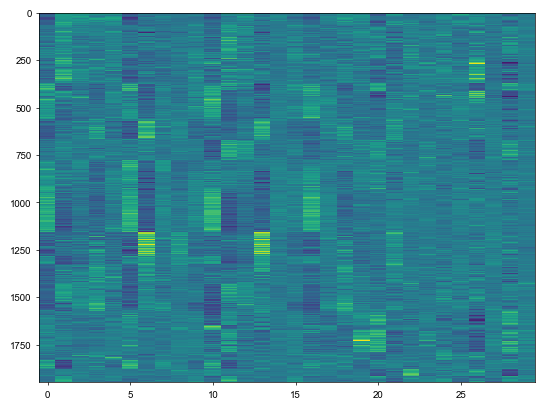

In [14]:
S_sorted = S[np.argsort(cluster_ids)]
plt.imshow(S_sorted, aspect="auto", interpolation="nearest")
plt.show()

### Save results

In [15]:
with pd.HDFStore(os.path.join(tmpdir, "result_combined.hdf5"), mode='w') as store:
    store.put('R', R)
    store.put('E', E)

### Visualize results

In [16]:
def reassign_cluster_ids(df):
    """
    Re-assign cluster IDs based on similarity
    """
    d = df[df["good"]].copy()
    X = d.filter(regex="^time_").to_numpy()
    cluster_ids = d["cluster"]
    cluster_means = np.array([X[cluster_ids == c].mean(axis=0) for c in np.unique(cluster_ids)])
    distance_matrix = dist.pdist(cluster_means, metric="cosine")
    Z = sch.linkage(distance_matrix, method="complete")
    row_order = sch.leaves_list(Z)

    # re-assign cluster ID based on the similarity
    lut = {}
    for (i, j) in enumerate(row_order):
        lut[j] = i
    lut[-1] = -1
    print(lut)

    df_out = df.copy()
    df_out['cluster'] = df_out['cluster'].replace(lut)

    return df_out

In [17]:
R = reassign_cluster_ids(R)

{np.int32(4): 0, np.int32(21): 1, np.int32(19): 2, np.int32(1): 3, np.int32(23): 4, np.int32(2): 5, np.int32(0): 6, np.int32(14): 7, np.int32(16): 8, np.int32(18): 9, np.int32(7): 10, np.int32(22): 11, np.int32(3): 12, np.int32(9): 13, np.int32(6): 14, np.int32(11): 15, np.int32(13): 16, np.int32(15): 17, np.int32(8): 18, np.int32(20): 19, np.int32(5): 20, np.int32(10): 21, np.int32(12): 22, np.int32(17): 23, -1: -1}


In [18]:
# make IDs start from 1
R.loc[(R["cluster"]>=0), "cluster"] += 1

In [19]:
R2 = R[R["good"]].copy()
R2.reset_index(inplace=True)
characterize_neurons(R2, E)

Figure saved as /flash/ReiterU/tmp/tomo_PSPIGMOZMACS/clustering.pdf


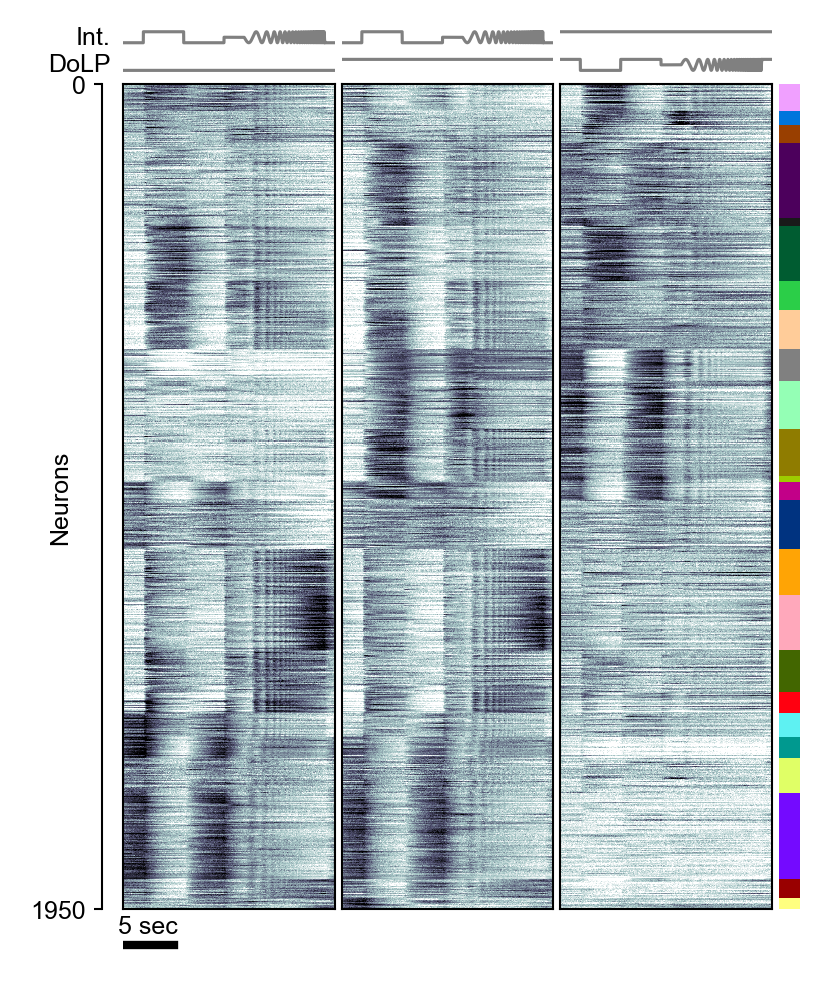

Figure saved as /flash/ReiterU/tmp/tomo_PSPIGMOZMACS/cluster_mean.pdf


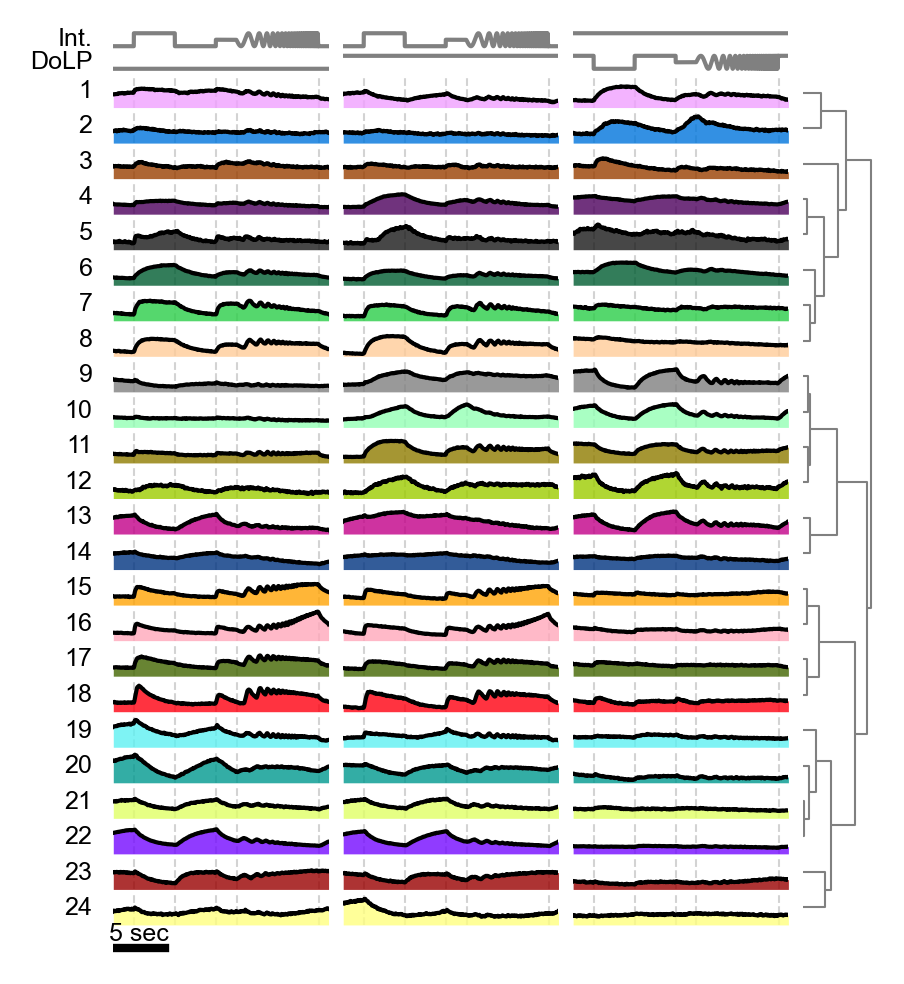

Figure saved as /flash/ReiterU/tmp/tomo_PSPIGMOZMACS/cluster_index.pdf


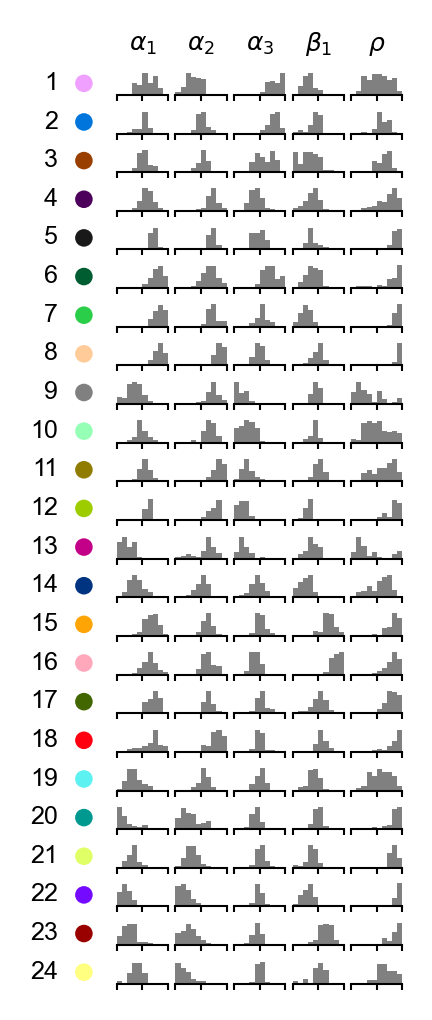

In [20]:
t = np.arange(21000) * 1e-3
stimulus = np.zeros_like(t)
stimulus[0:2000] = 0
stimulus[2000:6000] = 1
stimulus[6000:10000] = 0
stimulus[10000:12000] = 0.5
stimulus[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
stimulus[20000:21000] = 0

cluster_ids = R2["cluster"].sort_values().unique()

alphabet_colors = [
    "#F0A0FF", "#0075DC", "#993F00", "#4C005C", "#191919", "#005C31",
    "#2BCE48", "#FFCC99", "#808080", "#94FFB5", "#8F7C00", "#9DCC00",
    "#C20088", "#003380", "#FFA405", "#FFA8BB", "#426600", "#FF0010",
    "#5EF1F2", "#00998F", "#E0FF66", "#740AFF", "#990000", "#FFFF80",
    "#FFE100", "#FF5005"
]
alphabet_cmap = mpl.colors.ListedColormap(alphabet_colors, name='alphabet')
color_map = {i: alphabet_cmap(i-1) for i in np.unique(cluster_ids).astype("int")}

with mpl.rc_context(rc={'font.size': 6, 'axes.titlesize': 6, 'legend.fontsize': 6}):
    plot_clustering(R2, color_map, stimulus, vmin=-1.0, vmax=2.2, colormap_name="bone_r", figsize=(3.0,4.0), figsavename=os.path.join(tmpdir, "clustering.pdf"))
    plot_cluster_average(R2, color_map, stimulus, ymin=-1.5, ymax=2.5, figsize=(3.4,4.0), figsavename=os.path.join(tmpdir, "cluster_mean.pdf"))
    plot_index(R2, color_map, figsize=(1.5,4.0), figsavename=os.path.join(tmpdir, "cluster_index.pdf"))

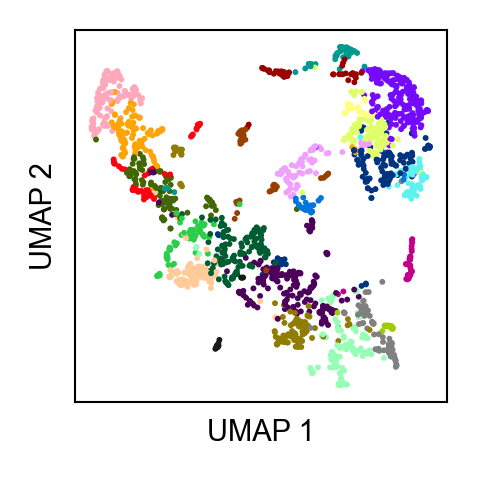

In [33]:
sc.pp.neighbors(adata, n_neighbors=7, metric='euclidean', use_rep='X_spca', random_state=2025)
sc.tl.umap(adata, n_components=2, min_dist=0.04, spread=3.0)

fig, ax = plt.subplots(figsize=(1.6,1.6), dpi=300)
um = adata.obsm['X_umap']
point_colors = [color_map[e] for e in R2["cluster"]]
scatter = ax.scatter(um[:, 0], um[:, 1], c=point_colors, s=2, alpha=1, lw=0)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "umap.pdf"), bbox_inches='tight')
plt.show()

### Copy data to bucket

In [34]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden/"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden/
cp -r /flash/ReiterU/tmp/tomo_BIPMEZOMPQCK/* /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden/
